# Comparison of two groups with three strata

When the individuals of each treatment group differ in another variable that affects survival, the treatments are compared inside each level (stratum) of that variable. In a stratified Cox model each stratum has its own baseline hazard, and the coefficient of the treatment is common to all of them.

The data are the survival times of 30 patients with melanoma who received one of two treatments, in three age groups.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter

In [2]:
# Colors shared by all the plots
GROUP_COLORS = {1: '#1f4e79', 2: '#E69F00'}

## The data

In [3]:
DatOriginal = pd.read_csv("data/melanoma_survival.dat", sep=r"\s+")

In [4]:
DatOriginal.head()

,age,treatment,time,status
0,1,1,19,1
1,1,1,24,0
2,1,1,8,1
3,1,1,17,0
4,1,1,17,0


The data has two treatments and three strata in the age.

In [5]:
DatOriginal.groupby(['age', 'treatment']).agg(patients=('time', 'size'), deaths=('status', 'sum')).unstack('treatment')

patients    deaths   
treatment        1  2      1  2
age                            
1                6  9      2  3
2                3  7      1  1
3                2  3      2  1

Kaplan-Meier estimator of each treatment in each age group. There are very few deaths in each stratum.

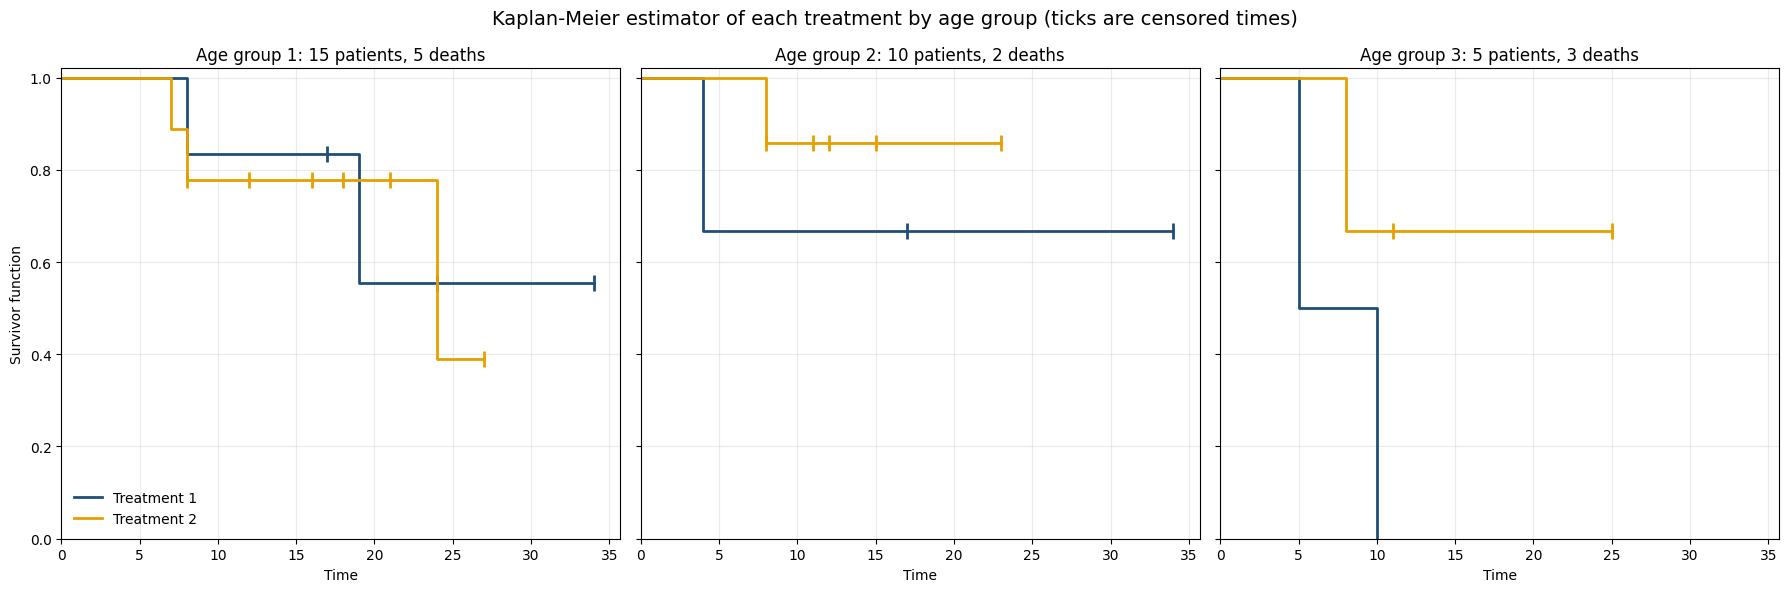

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
for ax, (age, DatStratum) in zip(axes, DatOriginal.groupby('age')):
    for treatment, DatGroup in DatStratum.groupby('treatment'):
        kmf = KaplanMeierFitter().fit(DatGroup['time'], event_observed=DatGroup['status'])
        surv = kmf.survival_function_.iloc[:, 0]
        censored = kmf.event_table.index[kmf.event_table['censored'] > 0]
        ax.step(surv.index, surv, where='post', color=GROUP_COLORS[treatment], lw=2, label=f'Treatment {treatment}')
        ax.plot(censored, surv.loc[censored], '|', color=GROUP_COLORS[treatment], markersize=11, markeredgewidth=2)
    ax.set_xlabel('Time')
    ax.set_title(f'Age group {age}: {len(DatStratum)} patients, {DatStratum["status"].sum()} deaths')
    ax.set_xlim(0, None)
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('Survivor function')
axes[0].legend(loc='lower left', frameon=False)
fig.suptitle('Kaplan-Meier estimator of each treatment by age group (ticks are censored times)', fontsize=14)
plt.tight_layout()

## Stratified Cox model

In [7]:
cph = CoxPHFitter()
cph.fit(DatOriginal, 'time', 'status', formula='C(treatment)', strata='age')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 30 total observations, 20 right-censored observations>
             duration col = 'time'
                event col = 'status'
                   strata = age
      baseline estimation = breslow
   number of observations = 30
number of events observed = 10
   partial log-likelihood = -19.35
         time fit was run = 2026-10-13 02:11:17 UTC

---
                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                          
C(treatment)[T.2] -0.53      0.59      0.65           -1.79            0.74                0.17                2.09

                   cmp to     z    p  -log2(p)
covariate                                     
C(treatment)[T.2]    0.00 -0.82 0.41      1.27
---
Concordance = 0.54
Partial AIC = 40.71
log-likelihood ratio test = 0.66 on 1 df
-log2(p) of ll-ratio test = 1.27

Because the $P$-value is 0.41 we conclude that there is no significance difference between survival times for the two treatments